# Gradient Descent, Decoded 🧩
**Decoded ML · Article 01** · by Arsum Javaid

In this notebook we teach a computer to find the best straight line through some noisy points, using nothing but NumPy and the idea of *a ball rolling downhill*.

> Companion to the Medium article *Every AI You've Ever Used Learned by Rolling Downhill*.

## 1. The data
We secretly generate points around the line **y = 3x + 2** and add noise. The model's job is to discover the 3 and the 2 on its own.

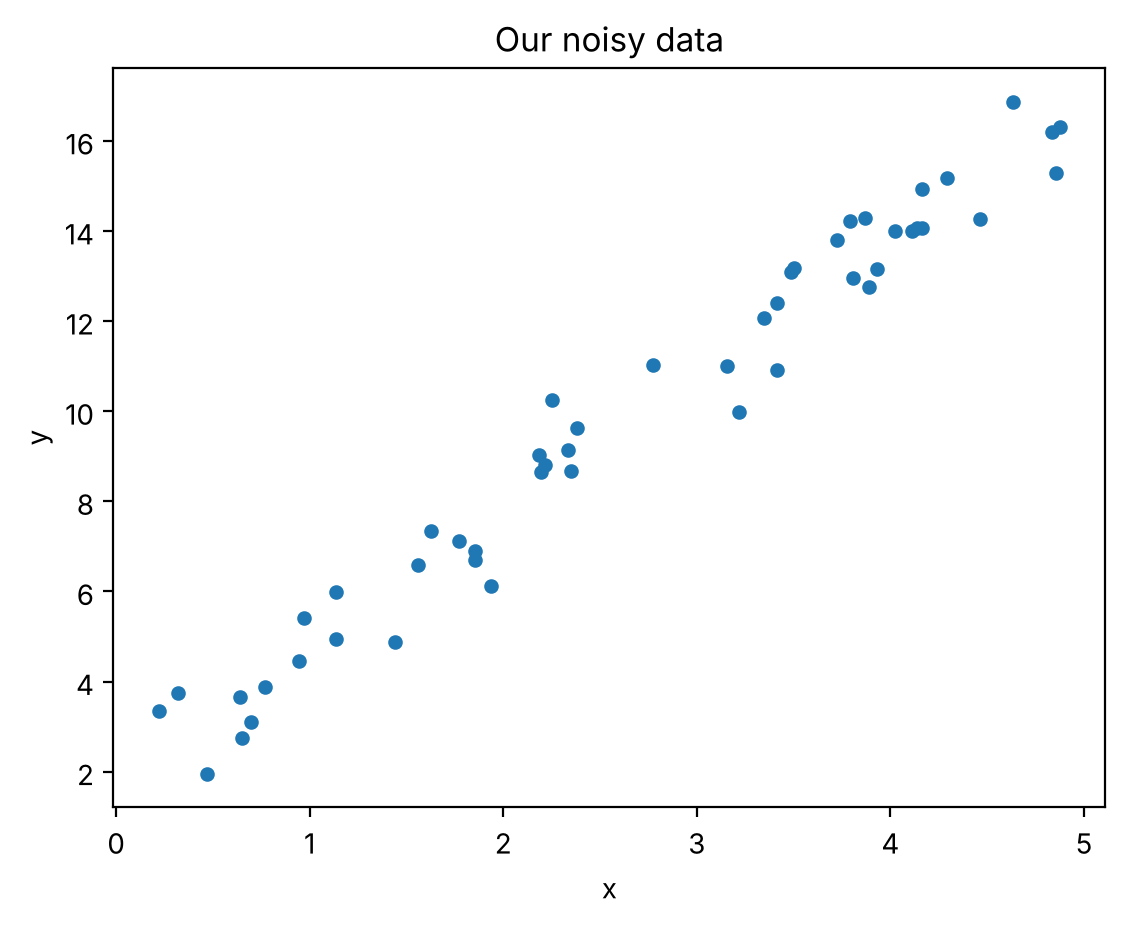

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
x = rng.uniform(0, 5, 50)
y = 3.0 * x + 2.0 + rng.normal(0, 1.0, 50)

plt.scatter(x, y, s=18)
plt.title('Our noisy data'); plt.xlabel('x'); plt.ylabel('y'); plt.show()

## 2. How wrong are we? (the loss)
The model guesses a line `y_pred = w*x + b`. We measure how wrong it is with **Mean Squared Error**: the average of (prediction − truth)².

This number is our *height on the hill*. High = bad, low = good.

In [2]:
def loss(w, b):
    y_pred = w * x + b
    return np.mean((y_pred - y) ** 2)

print('Loss of a terrible guess (w=0, b=0):', round(loss(0, 0), 2))
print('Loss of the true line   (w=3, b=2):', round(loss(3, 2), 2))

Loss of a terrible guess (w=0, b=0): 115.48
Loss of the true line   (w=3, b=2): 0.6


## 3. Which way is downhill? (the gradient)
The gradient tells us how the loss changes if we nudge `w` or `b` a tiny bit. Using basic calculus on the MSE:

- `dL/dw = 2 · mean(error · x)`
- `dL/db = 2 · mean(error)`

where `error = y_pred − y`. A positive gradient means "uphill is this way", so we step the *opposite* way.

In [3]:
def gradients(w, b):
    error = (w * x + b) - y
    dw = 2 * np.mean(error * x)
    db = 2 * np.mean(error)
    return dw, db

dw, db = gradients(0, 0)
print(f'Slope of the hill at (w=0, b=0):  dw = {dw:.2f},  db = {db:.2f}')

Slope of the hill at (w=0, b=0):  dw = -64.46,  db = -19.72


## 4. Roll downhill
The entire algorithm is three lines inside a loop:

```
feel the slope   → dw, db = gradients(w, b)
take a step      → w = w - lr * dw ;  b = b - lr * db
repeat
```
`lr` is the **learning rate**: how big each step is.

In [4]:
w, b, lr = 0.0, 0.0, 0.01
losses = []
for step in range(500):
    losses.append(loss(w, b))
    dw, db = gradients(w, b)
    w -= lr * dw
    b -= lr * db
    if step % 100 == 0:
        print(f'step {step:3d}  loss {losses[-1]:8.3f}  w {w:.3f}  b {b:.3f}')

print(f'\nLearned: y = {w:.2f}x + {b:.2f}   (true: y = 3x + 2)')

step   0  loss  115.478  w 0.645  b 0.197
step 100  loss    0.634  w 3.184  b 1.238
step 200  loss    0.601  w 3.132  b 1.410
step 300  loss    0.586  w 3.097  b 1.526
step 400  loss    0.579  w 3.074  b 1.604

Learned: y = 3.06x + 1.66   (true: y = 3x + 2)


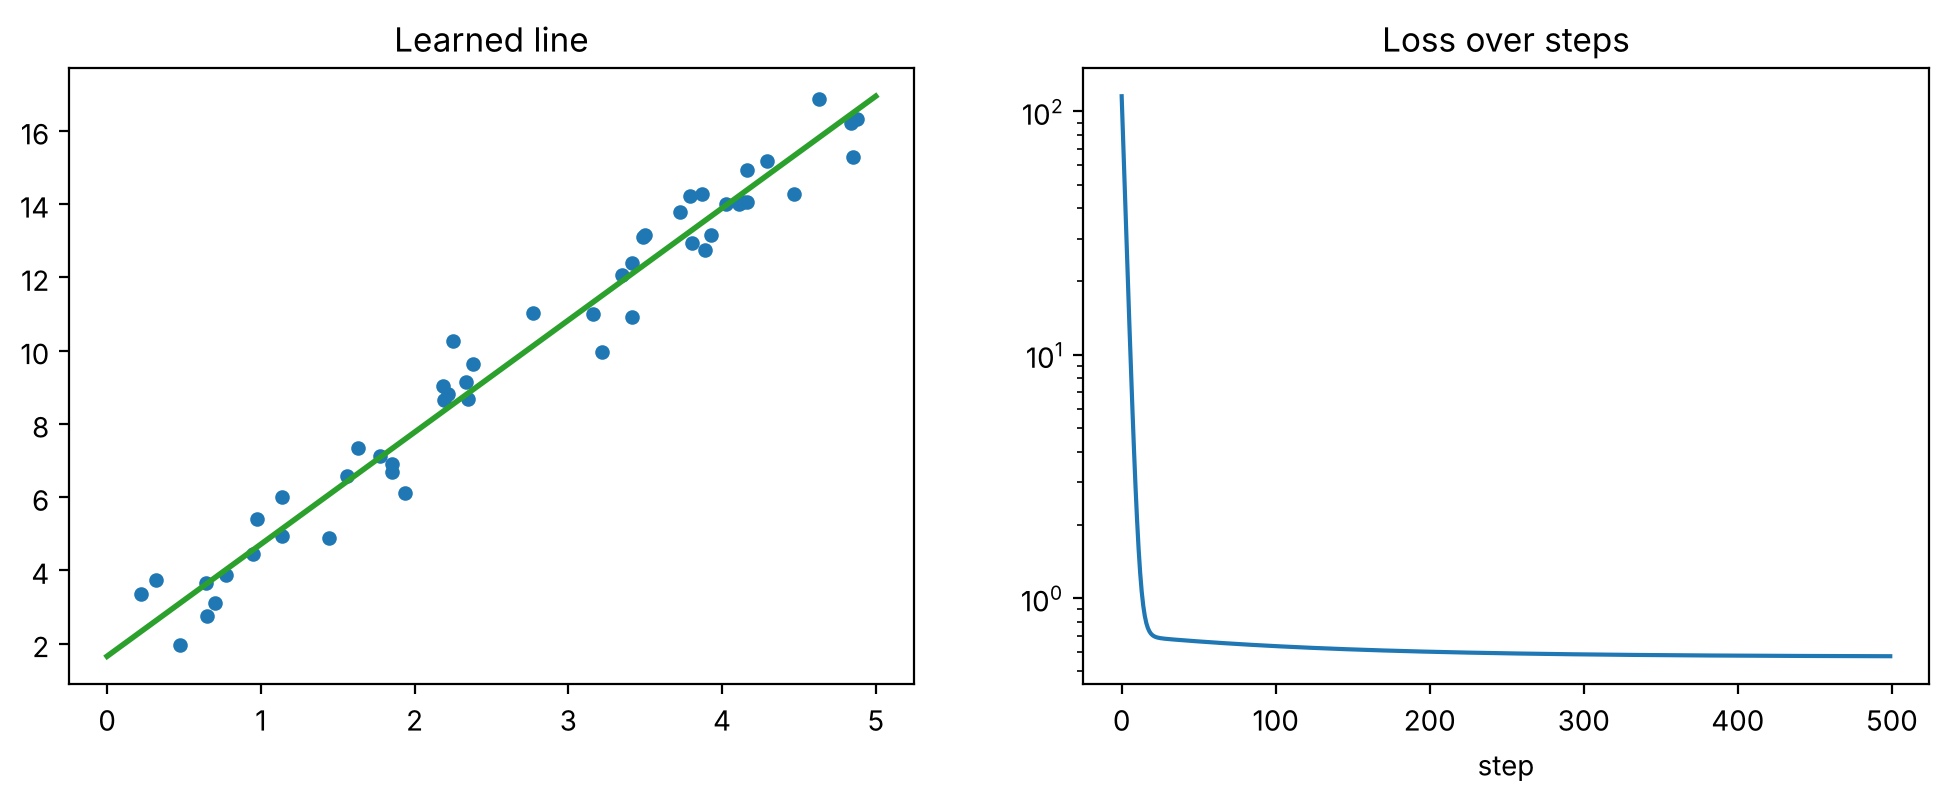

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.scatter(x, y, s=18); xs = np.linspace(0, 5, 50)
a1.plot(xs, w * xs + b, color='tab:green', lw=2); a1.set_title('Learned line')
a2.plot(losses); a2.set_yscale('log'); a2.set_title('Loss over steps'); a2.set_xlabel('step')
plt.show()

## 5. Play with the learning rate
Change `lr` below and re-run. Try `0.001`, `0.01`, `0.05`, then `0.15`. At some point the loss **explodes** instead of shrinking. That's the ball overshooting the valley.

In [6]:
def train(lr, steps=100):
    w, b, hist = 0.0, 0.0, []
    for _ in range(steps):
        hist.append(loss(w, b))
        dw, db = gradients(w, b)
        w, b = w - lr * dw, b - lr * db
    return hist

for lr in [0.001, 0.01, 0.05, 0.15]:
    h = train(lr)
    print(f'lr={lr:<6} final loss = {h[-1]:.3e}')

lr=0.001  final loss = 2.887e+00
lr=0.01   final loss = 6.343e-01
lr=0.05   final loss = 5.762e-01
lr=0.15   final loss = 2.094e+60


## 6. Takeaway
**Gradient descent = feel the slope, take a small step downhill, repeat.**

Every neural network, including the giant ones behind ChatGPT, trains with a variant of this exact loop. The only differences are many more parameters (billions instead of 2) and smarter step rules (like Adam).

➡️ Next in the series: **Overfitting**, or why memorizing is not learning.